In [1]:
import sys
print("Python executable:", sys.executable)

import re
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from transformers import BertTokenizerFast

print("All imports successful")

Python executable: c:\Users\sehba\OneDrive - Asia Pacific University of Technology And Innovation (APU)\Documents\fraud-detector-fyp\backend\venv\Scripts\python.exe
All imports successful


In [2]:
df = pd.read_csv("../data/raw/fake_job_postings.csv")

print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Shape (rows, columns): (17880, 18)

Column names:
['title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'in_balanced_dataset']


In [3]:
df.head(3)

,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,in_balanced_dataset
0,Marketing Intern,"US, NY, New York",Marketing,NaN,"<h3>We're Food52, and we've created a groundbr...","<p>Food52, a fast-growing, James Beard Award-w...",<ul>\r\n<li>Experience with content management...,NaN,f,t,f,Other,Internship,NaN,NaN,Marketing,f,f
1,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"<h3>90 Seconds, the worlds Cloud Video Product...",<p>Organised - Focused - Vibrant - Awesome!<br...,<p><b>What we expect from you:</b></p>\r\n<p>Y...,<h3><b>What you will get from us</b></h3>\r\n<...,f,t,f,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,f,f
2,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,<h3></h3>\r\n<p>Valor Services provides Workfo...,"<p>Our client, located in Houston, is actively...",<ul>\r\n<li>Implement pre-commissioning and co...,NaN,f,t,f,NaN,NaN,NaN,NaN,NaN,f,f


In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nClass balance (fraudulent):")
print(df["fraudulent"].value_counts())
print(df["fraudulent"].value_counts(normalize=True) * 100)

Missing values per column:
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                0
requirements            2689
benefits                7196
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
in_balanced_dataset        0
dtype: int64

Class balance (fraudulent):
fraudulent
f    17014
t      866
Name: count, dtype: int64
fraudulent
f    95.1566
t     4.8434
Name: proportion, dtype: float64


In [5]:
placeholder_pattern = re.compile(r"#[a-z]+_[0-9a-f]+#")

def clean_text(text):
    if not isinstance(text, str):
        text = ""

    # Parse as real HTML so <script>/<style> tag CONTENTS are discarded,
    # not just the tag markers themselves
    soup = BeautifulSoup(text, "html.parser")
    for element in soup(["script", "style"]):
        element.decompose()
    text = soup.get_text(separator=" ")

    text = text.lower()
    text = placeholder_pattern.sub(" ", text)     # remove EMSCAD's #URL_hash#, #EMAIL_hash#, #PHONE_hash# tokens
    text = re.sub(r"\\r\\n|\\n|\\r", " ", text)   # remove literal escaped newline sequences
    text = re.sub(r"http\S+|www\S+", " ", text)   # remove genuine URLs
    text = re.sub(r"[^a-z\s]", " ", text)         # remove remaining punctuation/digits
    text = re.sub(r"\s+", " ", text).strip()      # collapse whitespace

    return text

print("clean_text() defined successfully")

clean_text() defined successfully


In [6]:
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
combined_series = df[text_cols].fillna("").agg(" ".join, axis=1)

placeholder_check = re.compile(r"#[a-z]+_[0-9a-f]+#", re.IGNORECASE)
placeholder_mask = combined_series.str.contains(placeholder_check)
placeholder_sample = combined_series[placeholder_mask].iloc[0]

style_mask = combined_series.str.contains("<style", case=False, regex=False)
style_sample = combined_series[style_mask].iloc[0] if style_mask.sum() > 0 else None

normal_sample = combined_series.iloc[0]

print("Rows containing EMSCAD placeholders:", placeholder_mask.sum())
print("Rows containing <style> blocks:", style_mask.sum())

Rows containing EMSCAD placeholders: 8176
Rows containing <style> blocks: 53


In [7]:
print("=== Regression check (ordinary posting) ===")
print(clean_text(normal_sample)[:300])

print("\n=== EMSCAD placeholder removal check ===")
cleaned_placeholder = clean_text(placeholder_sample)
print("Placeholder pattern still present?", bool(placeholder_check.search(cleaned_placeholder)))
print(cleaned_placeholder[:300])

if style_sample is not None:
    print("\n=== <style> block check ===")
    cleaned_style = clean_text(style_sample)
    print(cleaned_style[:300])
else:
    print("\nNo rows with raw <style> tags found - skipping (already validated separately).")

=== Regression check (ordinary posting) ===
marketing intern we re food and we ve created a groundbreaking and award winning cooking site we support connect and celebrate home cooks and give them everything they need in one place we have a top editorial business and engineering team we re focused on using technology to find new and better way

=== EMSCAD placeholder removal check ===
Placeholder pattern still present? False
customer service cloud video production seconds the worlds cloud video production service seconds is the worlds cloud video production service enabling brands and agencies to get high quality online video content shot and produced anywhere in the world seconds makes video production fast affordable 

=== <style> block check ===
engagement manager south africa upstream s mission is to revolutionise the way companies market to consumers through cutting edge technology this is an opportunity to collaborate with like minded people in an environment that embraces individ

In [8]:
df["fraudulent"] = df["fraudulent"].map({"f": 0, "t": 1})

text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
for col in text_cols:
    df[col] = df[col].fillna("")

df["full_text"] = df[text_cols].agg(" ".join, axis=1)
df["clean_text"] = df["full_text"].apply(clean_text)

print("Preprocessing applied. df now has", df.shape[1], "columns.")

Preprocessing applied. df now has 20 columns.


In [9]:
print("Unique fraudulent values after conversion:", df["fraudulent"].unique())
print("Nulls in fraudulent after conversion:", df["fraudulent"].isnull().sum())
print("Row count unchanged:", df.shape[0])

print("\nNulls in clean_text:", df["clean_text"].isnull().sum())
print("Empty-string clean_text rows:", (df["clean_text"].str.strip() == "").sum())

placeholder_residue = df["clean_text"].str.contains(r"#[a-z]+_[0-9a-f]+#", regex=True).sum()
print("\nRows still containing raw placeholder pattern:", placeholder_residue)

print("\nSample cleaned rows:")
print(df[["clean_text", "fraudulent"]].sample(3, random_state=1))

Unique fraudulent values after conversion: [0 1]
Nulls in fraudulent after conversion: 0
Row count unchanged: 17880

Nulls in clean_text: 0
Empty-string clean_text rows: 0

Rows still containing raw placeholder pattern: 0

Sample cleaned rows:
                                              clean_text  fraudulent
5736   jr business analyst quality analyst entry leve...           0
7106   english teacher abroad we help teachers get sa...           0
11978  sql server database developer job opportunity ...           0


count    17880.000000
mean       393.242282
std        219.397587
min          4.000000
25%        236.000000
50%        369.000000
75%        516.000000
max       2152.000000
Name: clean_text, dtype: float64

50th percentile: 369 words
75th percentile: 516 words
90th percentile: 678 words
95th percentile: 798 words
99th percentile: 1025 words


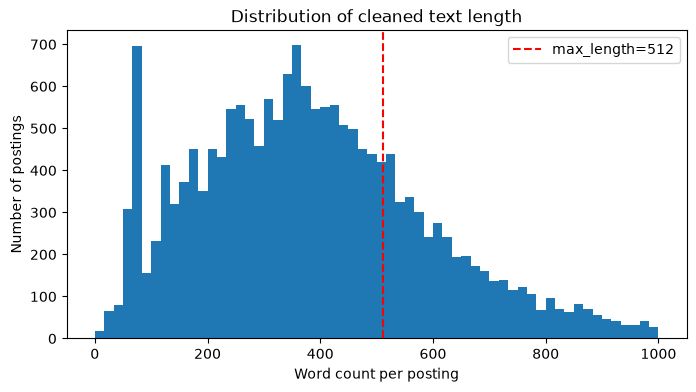

In [10]:
word_counts = df["clean_text"].str.split().str.len()

print(word_counts.describe())
print()
for pct in [50, 75, 90, 95, 99]:
    print(f"{pct}th percentile: {word_counts.quantile(pct/100):.0f} words")

plt.figure(figsize=(8, 4))
plt.hist(word_counts, bins=60, range=(0, 1000))
plt.axvline(512, color="red", linestyle="--", label="max_length=512")
plt.xlabel("Word count per posting")
plt.ylabel("Number of postings")
plt.legend()
plt.title("Distribution of cleaned text length")
plt.show()

In [11]:
tokenizer = BertTokenizerFast.from_pretrained("bert-base-uncased")

sample_texts = df["clean_text"].sample(2000, random_state=42).tolist()
token_lengths = np.array([len(tokenizer.tokenize(t)) for t in sample_texts])

print("Token length stats (sample of 2000 postings):")
print(f"  mean: {token_lengths.mean():.0f}")
print(f"  median: {np.median(token_lengths):.0f}")
print(f"  % exceeding 512 tokens: {(token_lengths > 512).mean()*100:.1f}%")
print(f"  % exceeding 256 tokens: {(token_lengths > 256).mean()*100:.1f}%")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (516 > 512). Running this sequence through the model will result in indexing errors


Token length stats (sample of 2000 postings):
  mean: 414
  median: 385
  % exceeding 512 tokens: 29.3%
  % exceeding 256 tokens: 73.0%


In [12]:
genuine_count = (df["fraudulent"] == 0).sum()
fraud_count = (df["fraudulent"] == 1).sum()

weight_genuine = 1.0
weight_fraud = genuine_count / fraud_count

print(f"Genuine postings: {genuine_count}")
print(f"Fraudulent postings: {fraud_count}")
print(f"Class weight (genuine): {weight_genuine:.2f}")
print(f"Class weight (fraudulent): {weight_fraud:.2f}")

Genuine postings: 17014
Fraudulent postings: 866
Class weight (genuine): 1.00
Class weight (fraudulent): 19.65


In [13]:
train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df["fraudulent"], random_state=42
)

val_fraction_of_remaining = 0.15 / 0.85
train_df, val_df = train_test_split(
    train_val_df, test_size=val_fraction_of_remaining,
    stratify=train_val_df["fraudulent"], random_state=42
)

print(f"Train: {len(train_df)} rows ({len(train_df)/len(df)*100:.2f}%)")
print(f"Val:   {len(val_df)} rows ({len(val_df)/len(df)*100:.2f}%)")
print(f"Test:  {len(test_df)} rows ({len(test_df)/len(df)*100:.2f}%)")

Train: 12516 rows (70.00%)
Val:   2682 rows (15.00%)
Test:  2682 rows (15.00%)


In [14]:
for name, split_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    fraud_count = split_df["fraudulent"].sum()
    fraud_pct = split_df["fraudulent"].mean() * 100
    print(f"{name}: {fraud_count} fraudulent / {len(split_df)} total ({fraud_pct:.2f}%)")


Train: 606 fraudulent / 12516 total (4.84%)
Val: 130 fraudulent / 2682 total (4.85%)
Test: 130 fraudulent / 2682 total (4.85%)


In [15]:
import os
os.makedirs("../data/processed", exist_ok=True)

cols_to_save = ["title", "clean_text", "fraudulent"]

train_df[cols_to_save].to_csv("../data/processed/train.csv", index_label="original_index")
val_df[cols_to_save].to_csv("../data/processed/val.csv", index_label="original_index")
test_df[cols_to_save].to_csv("../data/processed/test.csv", index_label="original_index")

print("Saved train.csv, val.csv, test.csv to ml/data/processed/")

Saved train.csv, val.csv, test.csv to ml/data/processed/


In [16]:
train_check = pd.read_csv("../data/processed/train.csv", index_col="original_index")
val_check = pd.read_csv("../data/processed/val.csv", index_col="original_index")
test_check = pd.read_csv("../data/processed/test.csv", index_col="original_index")

print("Shapes:")
print("Train:", train_check.shape)
print("Val:  ", val_check.shape)
print("Test: ", test_check.shape)

print("\nNulls in clean_text:")
print("Train:", train_check["clean_text"].isnull().sum())
print("Val:  ", val_check["clean_text"].isnull().sum())
print("Test: ", test_check["clean_text"].isnull().sum())

print("\nPlaceholder residue check (should be 0 across all three):")
for name, d in [("Train", train_check), ("Val", val_check), ("Test", test_check)]:
    residue = d["clean_text"].str.contains(r"#[a-z]+_[0-9a-f]+#", regex=True).sum()
    print(f"{name}: {residue}")

print("\nfraudulent dtype:", train_check["fraudulent"].dtype)

print("\nSample preview:")
print(train_check.head(2))

Shapes:
Train: (12516, 3)
Val:   (2682, 3)
Test:  (2682, 3)

Nulls in clean_text:
Train: 0
Val:   0
Test:  0

Placeholder residue check (should be 0 across all three):
Train: 0
Val: 0
Test: 0

fraudulent dtype: int64

Sample preview:
                                        title  \
original_index                                  
4086                        Technical Manager   
4740            iOS developer job description   

                                                       clean_text  fraudulent  
original_index                                                                 
4086            technical manager luxury british cocoa grower ...           0  
4740            ios developer job description we are looking f...           0  
